In [2]:
%load_ext autoreload
%autoreload 2
import xarray as xr
from CrocoDash.topo import Topo
from CrocoDash.grid import Grid
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [3]:
ocean_static = xr.open_dataset("/glade/derecho/scratch/manishrv/archive/gustavo-glorys-2/ocn/hist/gustavo-glorys-2.mom6.h.static.nc")
grid = Grid.from_supergrid("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")
topo = Topo.from_topo_file(grid,"/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_topo.nc", min_depth = 5)

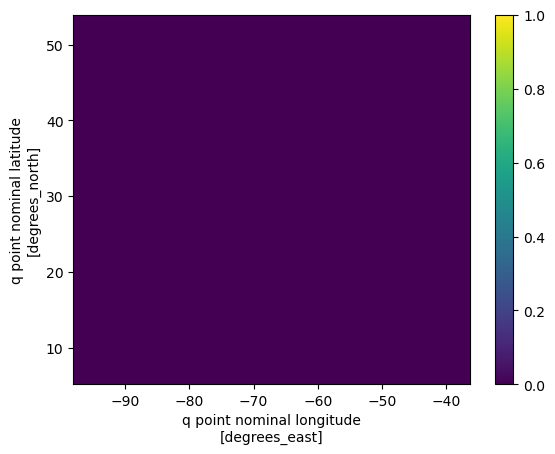

In [23]:
(topo.qmask-ocean_static.wet_c).plot()

In [25]:
np.where(topo.qmask-ocean_static.wet_c!=0)

(array([  0, 780]), array([740, 740]))

In [24]:
np.where(topo.vmask-ocean_static.wet_v!=0)

(array([], dtype=int64), array([], dtype=int64))

In [11]:
pan_ocean_static = xr.open_dataset("/glade/derecho/scratch/manishrv/archive/panama-hr-v2/ocn/hist/panama-hr-v2.mom6.h.static.nc")


In [20]:
pan_ocean_static.wet_c[0,0].item()

0.0

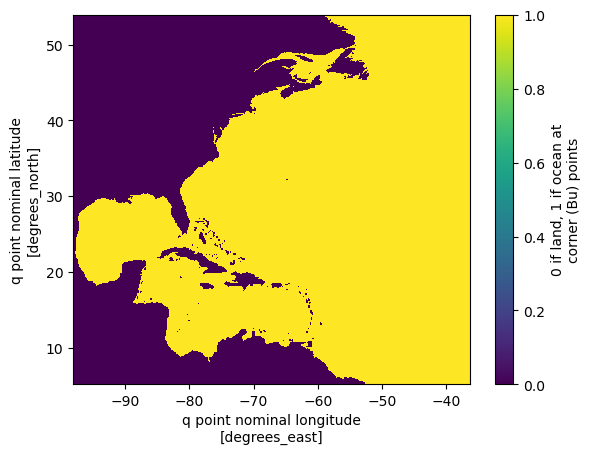

In [4]:
ocean_static.wet_c.plot()

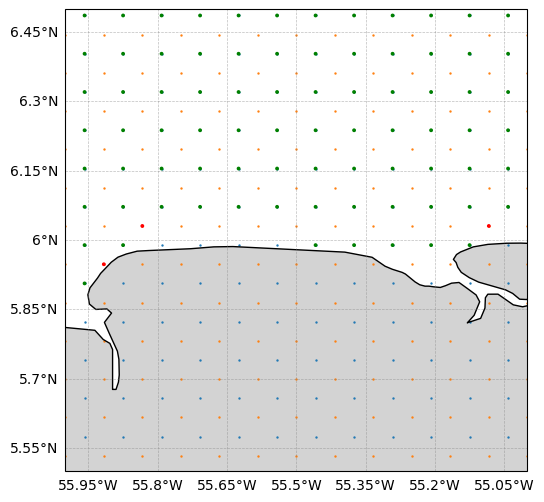

In [21]:
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
extent = [-56,-55,5.5,6.5]
ax.set_extent(extent, crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False
ax.scatter(grid.tlon, grid.tlat, s= 0.5)
ax.scatter(grid.qlon, grid.qlat, s= 0.5)

ax.scatter(grid.tlon, grid.tlat,topo.tmask*3, c="green")
ax.scatter(grid.qlon, grid.qlat,(topo.qmask-ocean_static.wet_c)*3, c="red")
